# Revisión de Calidad del Panel RBD (pre-análisis)

Antes de los mapas y el modelo, este notebook responde tres preguntas que afectan directamente al **target** de la tesis (la *brecha de recuperación* POST−PRE):

1. **Puntajes suprimidos / anómalos** — ¿hay establecimientos con el puntaje oculto (pocos alumnos) cuyo valor se haya colado como número y contamine los promedios?
2. **Años por establecimiento** — ¿cuántos años respaldan la brecha de cada colegio? ¿Qué mínimo conviene exigir?
3. **Regiones por año** — control del caso **Ñuble** (se separa de Biobío en 2018, sobre el corte pre/post).

Requiere haber corrido antes `01_construccion_panel.ipynb` (usa el archivo `simce_rbd_unificado_2015_2025.csv` ya enriquecido).

> **Revisión del 24-oct-2026 (auditoría de cuadernos y código).** Cambia una sola cosa en este cuaderno: `resultado.recuperacion_relativa` se calcula ahora **solo para los establecimientos que cayeron al menos 1 punto en 2022**. Antes se calculaba también para los que subieron (865 en la muestra analítica de Matemática), y la mediana mezclaba dos situaciones distintas: para una escuela que subió, el cociente no mide recuperación.

**Salida esperada en Matemática** (celda de `resumen_resultados`): `recuperacion_relativa` con n = 1.856 (antes 2.721), mediana 0,60 (antes 0,54), p25 0,08 y p75 1,42. `caida_inicial`, `recuperacion` y `brecha_simple` no cambian. En la tabla de ejemplos, las filas con caída positiva quedan con `recuperacion_relativa` vacía, que es lo correcto.

Después de este cuaderno hay que volver a ejecutar el 04 y el 05, que leen `resultados_mate_2m.csv`.

In [1]:
import sys
from pathlib import Path

for m in list(sys.modules):
    if m == "simce_panel" or m.startswith("simce_panel."):
        del sys.modules[m]

candidatos = [
    Path.cwd() / "simce_panel" / "src",   # notebook junto a la carpeta del proyecto
    Path.cwd().parent / "src",
    Path.cwd() / "src",
]
RUTA_SRC = next((p for p in candidatos
                 if (p / "simce_panel" / "__init__.py").exists()), None)
if RUTA_SRC is None:
    raise FileNotFoundError("No encontré 'src/simce_panel'. Ajusta RUTA_SRC.")
sys.path.insert(0, str(RUTA_SRC))

import pandas as pd
import simce_panel as sp
d = sp.diagnostico
print("simce_panel", sp.__version__, "| cargado desde", sp.__file__)

simce_panel 1.1.0 | cargado desde <ruta local>


In [2]:
# El notebook está junto a 'Dataset' -> BASE_DIR = "."
BASE_DIR = "."
cfg = sp.Config.desde_base(BASE_DIR)

# Carga los paneles ya generados en 01.
rbd = sp.io_datos.leer_csv(cfg.ruta_salida(sp.config.NOMBRES_SALIDA["rbd"]))
region = sp.io_datos.leer_csv(cfg.ruta_salida(sp.config.NOMBRES_SALIDA["region"]))
print("RBD:", rbd.shape, "| Region:", region.shape)

PRE  = [2015, 2016, 2017, 2018]
POST = [2022, 2023, 2024]

RBD: (23605, 65) | Region: (125, 28)


## 1. Puntajes suprimidos y valores anómalos

Primero inspeccionamos **todas** las columnas de puntaje: cuántos valores son numéricos, cuántos quedan vacíos (NaN) y, sobre todo, cuántos caen **fuera del rango plausible** de un puntaje SIMCE (por defecto 100–450). Un valor fuera de ese rango (un 0, un 99, etc.) es señal de un código de supresión colado como puntaje.

In [3]:
insp = d.inspeccionar_puntajes(rbd)   # rango_valido=(100, 450) por defecto
insp

,columna,n_total,n_numerico,n_nan,min,max,n_fuera_rango,ejemplos_fuera_rango
0,prom_lect2m_rbd,23605,23519,86,0.0,340.0,2,[0.0]
1,prom_mate2m_rbd,23605,23521,84,0.0,427.0,2,[0.0]
2,prom_soc2m_rbd,23605,5773,17832,179.0,347.0,0,[]
3,prom_nat2m_rbd,23605,5816,17789,154.0,345.0,0,[]


**Cómo leerlo:** si `n_fuera_rango` es 0 en todas las columnas, no hay sentinelas numéricos: los puntajes suprimidos ya vienen como vacío y se excluyen solos del promedio. Si aparece algún valor en `ejemplos_fuera_rango` (p. ej. `0.0`), ese código se está colando y hay que tratarlo (ver más abajo).

Ahora cruzamos la **marca** de Matemática con la presencia del puntaje, para confirmar que las filas marcadas como suprimidas no traen un número válido.

In [4]:
cm = d.cruce_marca_puntaje(rbd, materia="mate")
print("Columnas usadas -> puntaje:", cm.attrs.get("col_prom"),
      "| marca:", cm.attrs.get("col_marca"))
cm

Columnas usadas -> puntaje: prom_mate2m_rbd | marca: marca_mate2m_rbd


,marca,n_filas,con_puntaje,sin_puntaje,min_puntaje,max_puntaje
7,<NA>,22911,22843,68,136.0,427.0
1,2.0,516,516,0,164.0,372.0
4,Ajenas a la Agencia: Resultados no representat...,120,120,0,174.0,339.0
5,Ajenas al Establecimiento: Resultados no repre...,33,33,0,191.0,336.0
0,1.0,13,6,7,0.0,351.0
6,Alumnos insuficientes,7,0,7,NaN,NaN
2,3.0,4,2,2,244.0,295.0
3,4.0,1,1,0,192.0,192.0


**Cómo leerlo:** para cada valor de la marca, `con_puntaje` debería ser >0 solo en las marcas de "puntaje válido". Si una marca de supresión muestra `con_puntaje > 0` con `min_puntaje`/`max_puntaje` sospechosos (p. ej. 0), confirma la fuga.

**Saneamiento (activado).** Pone en NaN los puntajes no confiables para que no contaminen los promedios del target:

- **Sentinelas bajos** (`< 100`, p. ej. los `0.0` que son códigos de supresión).
- **Resultados no representativos** — filas cuya `marca_*` dice "no representativos", "ajenas a la Agencia/Establecimiento" o "alumnos insuficientes" (aunque traigan número).

Los **valores altos** se **conservan** a propósito. La escala SIMCE es relativa (promedio 250, desviación 50) y no define un máximo: el 400 que aparece en la documentación de los Estándares de Aprendizaje es el tope del eje con que se reportan los niveles de logro, no un techo de la escala. Un promedio de 420 equivale a 3,4 desviaciones sobre la media, excepcional pero posible. La celda siguiente los lista para inspección.

In [5]:
# Saneamiento de puntajes (sentinelas bajos + resultados no representativos).
# max_valido=None => NO toca los valores altos (se inspeccionan aparte).
rbd, reporte_saneo = sp.diagnostico.sanear_puntajes(
    rbd,
    materias=("lect", "mate"),   # materias longitudinales (presentes todos los años)
    min_valido=100,
    max_valido=None,
    inplace=False,
)
reporte_saneo

,materia,columna,n_validos_inicial,n_bajos_a_nan,n_altos_a_nan,n_no_repr_a_nan,n_validos_final
0,lect,prom_lect2m_rbd,23519,2,0,143,23374
1,mate,prom_mate2m_rbd,23521,2,0,153,23366


In [6]:
# Inspección de los valores altos (>400) que se conservaron, para decidir a mano.
from simce_panel.io_datos import a_numerico
cols_inspeccion = [c for c in ["año", "rbd", "nom_rbd",
                               "prom_mate2m_rbd", "marca_mate2m_rbd"]
                   if c in rbd.columns]
altos = rbd[a_numerico(rbd["prom_mate2m_rbd"]) > 400]
print(f"Establecimientos con puntaje de Matemática > 400: {len(altos)}")
altos[cols_inspeccion].head(20)

Establecimientos con puntaje de Matemática > 400: 11


[Salida omitida en la versión pública: mostraba nombres de establecimientos.]


## 2. Variables de resultado

La medida usada inicialmente —promedio POST menos promedio PRE— **mide el cambio de nivel, no la recuperación**. Confunde en un solo número el piso alcanzado en 2022 con el rebote de los años siguientes: dos establecimientos con idéntica diferencia de promedios pueden haber seguido trayectorias opuestas.

Se construyen tres medidas complementarias:

| Medida | Qué mide | Interpretación |
|---|---|---|
| `caida_inicial` | 2022 − promedio PRE (2015–2018) | impacto inicial, en puntos |
| `recuperacion` | pendiente de la recta sobre 2022–2025 | puntos ganados **por año** |
| `recuperacion_relativa` | recuperado hasta 2025 ÷ magnitud de la caída; solo si cayó al menos 1 punto | 1 = volvió a su nivel previo; 0 = no recuperó nada; negativo = siguió bajando |

Se conserva `brecha_simple` **solo** por comparabilidad con los reportes oficiales de la Agencia; no es la variable de análisis.

In [7]:
# Detecta la columna de Matemática real de tu base.
col_mate = (d.columnas_por_fragmentos(rbd, "prom", "mate", "2m") or [None])[0]
print("Columna de Matemática:", col_mate)

R = sp.resultado
print("PRE :", R.ANIOS_PRE)
print("POST:", R.ANIOS_POST, "| año de impacto:", R.ANIO_IMPACTO)

Columna de Matemática: prom_mate2m_rbd
PRE : (2015, 2016, 2017, 2018)
POST: (2022, 2023, 2024, 2025) | año de impacto: 2022


### 2.1 Elección de los umbrales mínimos

Cuántos establecimientos sobreviven a cada combinación de años mínimos exigidos en cada período. Sirve para elegir los umbrales con evidencia y documentar el compromiso entre precisión y tamaño de muestra.

La pendiente exige **al menos 3 años POST**: con dos puntos queda determinada por el ruido de dos mediciones.

In [8]:
R.cobertura_por_umbral(rbd, col_mate)

,min_pre=1,min_pre=2,min_pre=3,min_pre=4
min_post,,,,
1,2866,2831,2776,2599
2,2863,2828,2773,2596
3,2860,2825,2770,2593
4,2830,2795,2744,2569


In [9]:
MIN_PRE  = 2   # años válidos mínimos en 2015-2018
MIN_POST = 3   # años válidos mínimos en 2022-2025 (para estimar la pendiente)

resultados = R.construir_resultados(
    rbd, col_mate,
    min_pre=MIN_PRE, min_post=MIN_POST,
    incluir_brecha_simple=True,   # solo como referencia comparativa
)
print("Establecimientos:", len(resultados))
print("Muestra analítica (ambas medidas válidas):",
      int(resultados.muestra_analitica.sum()))
resultados.head()

Establecimientos: 3144
Muestra analítica (ambas medidas válidas): 2821


,rbd,puntaje_pre,n_pre,puntaje_impacto,caida_inicial,recuperacion,n_post,recuperacion_relativa,puntaje_post_medio,puntaje_post_ultimo,anio_post_ultimo,puntaje_post_prom,brecha_simple,latitud,longitud,muestra_analitica
0,1,197.333333,3.0,242.0,44.666667,5.9,4,NaN,242.25,243.0,2025.0,242.25,44.916667,-18.487200,-70.295212,True
1,4,281.250000,4.0,283.0,1.750000,4.6,4,NaN,288.00,297.0,2025.0,288.00,6.750000,-18.474239,-70.308273,True
2,5,285.250000,4.0,251.0,-34.250000,2.9,4,0.729927,265.25,276.0,2025.0,265.25,-20.000000,-18.476900,-70.313454,True
3,7,211.250000,4.0,225.0,13.750000,6.6,4,NaN,231.50,241.0,2025.0,231.50,20.250000,-18.476151,-70.288368,True
4,8,222.750000,4.0,236.0,13.250000,9.8,4,NaN,251.50,268.0,2025.0,251.50,28.750000,-18.482491,-70.317581,True


### 2.1b Exigencia explícita del puntaje de 2022 (revisión del 1-oct, comentario 22)

El criterio "al menos dos años válidos en PRE y tres en POST" no garantiza por sí solo que exista el puntaje de 2022, del que depende la caída inicial. La caída se calcula solo si existe ese puntaje, de modo que la exigencia ya operaba en el código; aquí se hace explícita y se cuantifica.

In [10]:
v = rbd.assign(_y=sp.io_datos.a_numerico(rbd[col_mate])).dropna(subset=["_y"])
npre = v[v["año"].between(2015, 2018)].groupby("rbd")["año"].nunique()
npost = v[v["año"].between(2022, 2025)].groupby("rbd")["año"].nunique()
con_2022 = set(v.loc[v["año"] == 2022, "rbd"])
cumplen = set(npre[npre >= MIN_PRE].index) & set(npost[npost >= MIN_POST].index)
print(f"Cumplen {MIN_PRE} PRE y {MIN_POST} POST: {len(cumplen)}")
print(f"De ellos, sin puntaje 2022 (excluidos): {len(cumplen - con_2022)}")

Cumplen 2 PRE y 3 POST: 2825
De ellos, sin puntaje 2022 (excluidos): 4


### 2.2 Descripción de las tres medidas

In [11]:
R.resumen_resultados(resultados)

,medida,n,media,desv,min,p25,mediana,p75,max
0,caida_inicial,2826,-10.78,23.32,-90.50,-26.50,-9.75,5.00,124.75
1,recuperacion,2978,3.47,6.87,-42.00,-0.60,3.20,7.30,37.60
2,recuperacion_relativa,1856,1.13,3.38,-27.20,0.08,0.60,1.42,43.20
3,brecha_simple,2866,-5.15,21.57,-82.25,-19.50,-3.75,9.23,98.25


**Cómo leerlo.** `caida_inicial` negativa indica cuántos puntos perdió el establecimiento en 2022 respecto de su nivel pre-pandemia. `recuperacion` positiva indica cuántos puntos gana por año desde entonces. `recuperacion_relativa` cercana a 1 significa que ya recuperó lo perdido; cercana a 0, que solo detuvo el deterioro; negativa, que siguió bajando. Solo existe para los establecimientos que cayeron en 2022: para los que subieron, el cociente no tiene interpretación.

Compara la mediana de `brecha_simple` con las otras dos: la medida antigua resume en un número lo que en realidad son dos fenómenos distintos.

In [12]:
# Demostración de por qué la medida antigua era insuficiente:
# establecimientos con brecha_simple casi idéntica pero trayectorias opuestas.
m = resultados[resultados.muestra_analitica].copy()
banda = m[m.brecha_simple.between(-6, -4)]
ejemplos = pd.concat([
    banda.nlargest(3, "recuperacion"),
    banda.nsmallest(3, "recuperacion"),
])
ejemplos[["rbd", "brecha_simple", "caida_inicial",
          "recuperacion", "recuperacion_relativa"]]

,rbd,brecha_simple,caida_inicial,recuperacion,recuperacion_relativa
536,3163,-5.50,-19.25,18.5,3.636364
1392,9646,-5.25,-37.75,18.0,1.377483
2787,25418,-5.75,-21.50,12.5,1.627907
476,2681,-4.00,0.25,-7.7,NaN
3070,31509,-6.00,1.50,-5.8,NaN
2460,22027,-4.25,12.75,-5.4,NaN


### 2.3 Distribución de las medidas

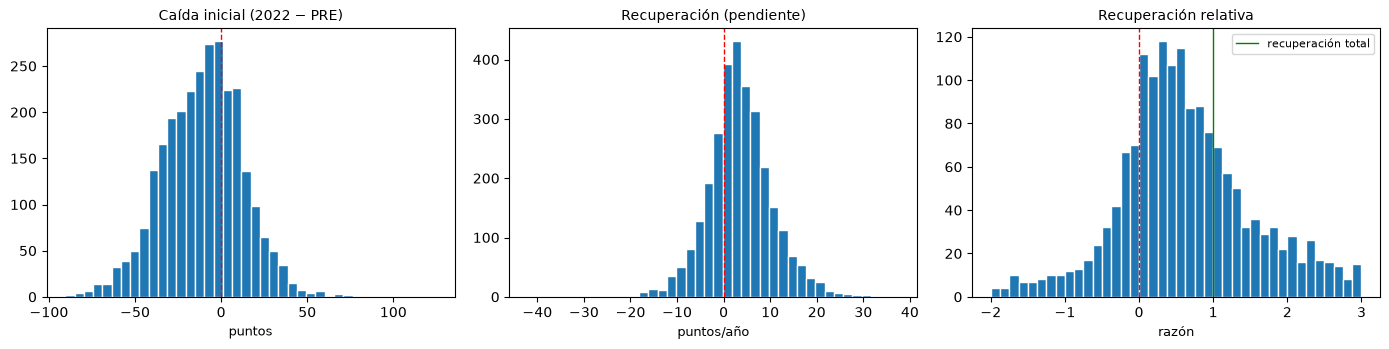

In [13]:
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, (col, titulo, unidad) in zip(axes, [
            ("caida_inicial",         "Caída inicial (2022 − PRE)", "puntos"),
            ("recuperacion",          "Recuperación (pendiente)",   "puntos/año"),
            ("recuperacion_relativa", "Recuperación relativa",      "razón")]):
        s = resultados[col].dropna()
        if col == "recuperacion_relativa":      # recorta la cola para que se vea
            s = s[s.between(-2, 3)]
        ax.hist(s, bins=40, edgecolor="white")
        ax.axvline(0, color="red", ls="--", lw=1)
        if col == "recuperacion_relativa":
            ax.axvline(1, color="green", ls="-", lw=1, label="recuperación total")
            ax.legend(fontsize=8)
        ax.set_title(titulo, fontsize=10)
        ax.set_xlabel(unidad, fontsize=9)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib no disponible.")

### 2.4 Rupturas de nivel: casos extremos

Una parte de los establecimientos presenta caídas o alzas iniciales superiores a 40 puntos. Vale la pena detenerse en ellos, porque **no son lo que parecen**.

Dos explicaciones intuitivas quedan descartadas por los propios datos:

- *No es ruido de muestra pequeña*: la gran mayoría de estos casos tiene 20 o más estudiantes evaluados, y los más extremos superan los 200. Con esa matrícula, una caída de 70 puntos equivale a más de 20 errores estándar.
- *No es una línea base inestable*: la correlación entre la magnitud de la caída y la dispersión interna del período PRE es prácticamente nula.

Lo que sí los distingue es si el cambio **persiste** en 2023–2025. Eso separa una ruptura estructural de nivel de una medición anómala de 2022.

In [14]:
resultados = R.clasificar_cambio_nivel(rbd, resultados, col_mate)
print(resultados.tipo_trayectoria.value_counts().to_string())

rup = resultados[resultados.ruptura_sostenida]
print(f"\nRupturas sostenidas: {len(rup)}"
      f" | al alza: {int((rup.caida_inicial > 0).sum())}"
      f" | a la baja: {int((rup.caida_inicial < 0).sum())}")

tipo_trayectoria
normal               2492
sin dato              321
ruptura sostenida     213
atípico 2022          118

Rupturas sostenidas: 213 | al alza: 19 | a la baja: 194


In [15]:
# Ejemplos de cada tipo, para verificar que la clasificación es razonable.
cols = ["rbd", "puntaje_pre", "puntaje_impacto", "caida_inicial",
        "puntaje_tardio", "desvio_tardio", "tipo_trayectoria"]
pd.concat([
    resultados[resultados.tipo_trayectoria == "ruptura sostenida"].nsmallest(3, "caida_inicial"),
    resultados[resultados.tipo_trayectoria == "atípico 2022"].nsmallest(3, "caida_inicial"),
])[cols].round(1)

,rbd,puntaje_pre,puntaje_impacto,caida_inicial,puntaje_tardio,desvio_tardio,tipo_trayectoria
1617,10685,334.5,244.0,-90.5,271.7,-62.8,ruptura sostenida
1019,7773,316.2,227.0,-89.2,244.0,-72.2,ruptura sostenida
1572,10506,304.5,222.0,-82.5,250.0,-54.5,ruptura sostenida
2925,26028,319.0,238.0,-81.0,300.3,-18.7,atípico 2022
1848,12800,283.7,213.0,-70.7,262.7,-21.0,atípico 2022
1768,12090,313.0,248.0,-65.0,303.3,-9.7,atípico 2022


**Distribución.** La pregunta que decide el tratamiento: ¿se reparten de forma pareja o se concentran en algún segmento? Si se concentran, no son un problema de calidad de datos sino un fenómeno sustantivo que el análisis debe explicar.

In [16]:
ancho = sp.io_datos.leer_csv(
    cfg.ruta_salida("simce_rbd_ancho_2015_2025.csv"),
    usecols=["rbd", "cod_depe1_cat", "cod_grupo_cat",
             "cod_rural_rbd_cat", "nom_reg_rbd"])

distrib = R.distribucion_rupturas(
    resultados, ancho,
    ["cod_grupo_cat", "cod_depe1_cat", "cod_rural_rbd_cat"])

for atributo, tabla in distrib.items():
    print(f"=== {atributo}")
    display(tabla)

=== cod_grupo_cat


tipo_trayectoria,atípico 2022,normal,ruptura sostenida,sin dato,pct_ruptura
cod_grupo_cat,,,,,
Medio alto,28,275,51,23,13.5
Medio,25,555,92,84,12.2
Medio bajo,18,735,43,101,4.8
Alto,39,374,16,51,3.3
Bajo,8,553,11,62,1.7


=== cod_depe1_cat


tipo_trayectoria,atípico 2022,normal,ruptura sostenida,sin dato,pct_ruptura
cod_depe1_cat,,,,,
Particular subvencionado,68,1293,160,182,9.4
Corporación de administración delegada,2,63,5,0,7.1
Servicio Local de Educación,5,287,14,22,4.3
Municipal DAEM,2,371,18,40,4.2
Particular pagado,38,367,13,62,2.7
Municipal Corporación,3,111,3,15,2.3


=== cod_rural_rbd_cat


tipo_trayectoria,atípico 2022,normal,ruptura sostenida,sin dato,pct_ruptura
cod_rural_rbd_cat,,,,,
Urbano,116,2346,211,286,7.1
Rural,2,146,2,35,1.1


**Cómo leerlo.** La columna `pct_ruptura` es la proporción de establecimientos de cada categoría que sufrió una ruptura sostenida. Si el porcentaje fuera parejo entre categorías, se trataría de ruido repartido al azar. Una concentración marcada indica lo contrario.

La variable `ruptura_sostenida` queda guardada en la tabla de resultados y puede usarse de tres formas: como control en el modelo, como criterio de exclusión en un análisis de sensibilidad, o como objeto de estudio propio en el análisis espacial.

### 2.5 ¿Son rupturas de aprendizaje o cambios de población?

Antes de interpretar las rupturas como pérdida de aprendizaje hay que descartar la explicación alternativa más plausible: que el establecimiento haya cambiado de **población**. Si un colegio perdió matrícula acomodada, bajarían a la vez su grupo socioeconómico y su puntaje, y estaríamos midiendo movilidad de estudiantes en lugar de aprendizaje.

La verificación compara, entre tipos de trayectoria, el cambio de GSE y la variación de matrícula entre PRE y POST.

In [17]:
# El GSE del panel largo viene como código en algunos años: se armoniza.
rbd, _ = sp.estandarizacion.estandarizar_canonico(rbd, variables=["cod_grupo"])

composicion = R.cambio_composicion(rbd)
verif = R.verificar_confundidor_composicional(resultados, composicion)

print("=== Resumen por tipo de trayectoria ===")
display(verif["resumen"])
print("=== Dirección del cambio de GSE (% por fila) ===")
display(verif["tabla_gse"])
print("=== Correlación con la caída inicial ===")
display(verif["correlaciones"])

=== Resumen por tipo de trayectoria ===


,n,delta_gse_medio,pct_bajo_gse,var_matricula_mediana,pct_perdio_matricula
tipo_trayectoria,,,,,
atípico 2022,118,0.04,9.32,1.66,12.71
normal,2492,0.03,8.59,2.14,14.57
ruptura sostenida,213,-0.08,13.62,3.50,6.10
sin dato,321,0.09,0.93,34.26,2.80


=== Dirección del cambio de GSE (% por fila) ===


delta_gse,bajó de GSE,sin cambio,subió de GSE
tipo_trayectoria,,,
atípico 2022,9.3,77.1,13.6
normal,8.6,80.6,10.8
ruptura sostenida,13.6,82.2,4.2
sin dato,7.0,76.7,16.3


=== Correlación con la caída inicial ===


,variable,corr_muestra_completa,corr_solo_rupturas
0,delta_gse,0.173,0.391
1,var_matricula,0.041,0.171


**Cómo leerlo.** Si las rupturas fueran composicionales, esperaríamos que el grupo con `ruptura sostenida` mostrara una caída marcada de matrícula y una proporción alta de establecimientos que bajaron de GSE, muy por encima del grupo `normal`. Diferencias pequeñas entre grupos indican que el cambio de composición **no** explica la ruptura.

La columna `corr_solo_rupturas` mide, dentro de los establecimientos con ruptura, cuánto covaría la magnitud de la caída con el cambio de composición. Un valor moderado sugiere que la composición contribuye en parte, pero no que la determine.

### 2.6 Guardado de las variables de resultado

Se guardan las tablas de Matemática y Lectura. Ambas incluyen las tres medidas,
los conteos de años válidos, la clasificación de trayectoria y las coordenadas,
por lo que quedan listas para el análisis espacial y el modelamiento.

In [18]:
ruta_res = cfg.ruta_salida("resultados_mate_2m.csv")
sp.io_datos.escribir_csv(resultados, ruta_res)
print("Variables de resultado guardadas en:", ruta_res)

# Lectura: misma construcción para Lectura, como contraste de H3.
col_lect = (d.columnas_por_fragmentos(rbd, "prom", "lect", "2m") or [None])[0]
resultados_lect = R.construir_resultados(rbd, col_lect,
                                         min_pre=MIN_PRE, min_post=MIN_POST)
sp.io_datos.escribir_csv(resultados_lect, cfg.ruta_salida("resultados_lect_2m.csv"))
print("Lectura:", int(resultados_lect.muestra_analitica.sum()), "establecimientos")
R.resumen_resultados(resultados_lect)

Variables de resultado guardadas en: Dataset\Unificados\resultados_mate_2m.csv


Lectura: 2818 establecimientos


,medida,n,media,desv,min,p25,mediana,p75,max
0,caida_inicial,2824,-4.58,17.93,-83.67,-16.75,-4.88,6.50,87.5
1,recuperacion,2977,2.03,5.99,-41.50,-1.50,2.20,5.70,37.4
2,recuperacion_relativa,1683,0.97,2.97,-26.67,0.09,0.73,1.45,38.4
3,brecha_simple,2866,-0.50,14.93,-50.50,-10.25,-1.00,8.69,70.0


## 3. Regiones por año — caso Ñuble

Verificamos cuántas regiones aparecen cada año. El salto de 15 a 16 marca la creación de **Ñuble** (separada de Biobío en 2018), que ocurre justo sobre el corte pre/post.

In [19]:
d.conteo_regiones_por_anio(region)

,año,n_regiones,codigos
0,2015,15,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
1,2016,15,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
2,2017,15,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
3,2018,16,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
4,2022,16,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
5,2023,16,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
6,2024,16,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
7,2025,16,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."


**Decisión metodológica:** como Ñuble no existe como unidad en el periodo PRE, para comparaciones regionales pre/post tienes dos opciones limpias:

- **Fusionar** Ñuble (16) con Biobío (8) en todo el periodo, tratándolas como una sola región histórica; o
- **Excluir** ambas de los análisis regionales que crucen el corte 2018.

A nivel **RBD** (tu unidad de análisis principal) el problema es menor: cada colegio conserva su `rbd` aunque su región administrativa cambie de nombre/código. Conviene fijar la región de cada RBD usando un único año de referencia (p. ej. la más reciente) en vez de la del año de cada fila.

---
### Resumen de la revisión

| Chequeo | Resultado esperado | Acción si falla |
|---|---|---|
| Puntajes fuera de rango | bajos saneados; altos a revisar | inspeccionar los >400 a mano |
| Marca vs puntaje | no-representativos a NaN | (lo hace `sanear_puntajes`) |
| Años por periodo | mínimo razonable de RBD | ajustar `MIN_PRE`/`MIN_POST` |
| Variables de resultado | caída, pendiente y recuperación relativa | revisar umbrales |
| Regiones por año | 15→16 en 2018 (Ñuble) | fusionar o excluir Biobío/Ñuble |

**Salidas:** `resultados_mate_2m.csv` y `resultados_lect_2m.csv` en `Dataset/Unificados/`, con las tres variables de resultado por establecimiento, listas para el análisis espacial y el modelamiento.